In [15]:
#8.Create a Neural network architecture from scratch in Python and use it to do multi-class classification on any data. Parameters to be considered while creating the neural network from scratch are specified as: (1) No of hidden layers : 1 or more (2) No. of neurons in hidden layer: 100 (3) Non-linearity in the layer : Relu (4) Use more than 1 neuron in the output layer. Use a suitable threshold value Use appropriate Optimization algorithm

Dataset Shape: (150, 4)
Number of Classes: 3
Epoch: 100 Loss: 0.3214
Epoch: 200 Loss: 0.2718
Epoch: 300 Loss: 0.2448
Epoch: 400 Loss: 0.226
Epoch: 500 Loss: 0.2114
Epoch: 600 Loss: 0.1992
Epoch: 700 Loss: 0.1888
Epoch: 800 Loss: 0.1796
Epoch: 900 Loss: 0.1714
Epoch: 1000 Loss: 0.1639

Neural Network Results
Hidden Neurons : 100
Activation     : ReLU
Output Neurons : 3
Output Function: Softmax
Optimizer      : Gradient Descent
Learning Rate  : 0.01
Epochs         : 1000

Actual Classes:    [0 2 1 1 0 1 0 0 2 1 2 2 2 1 0 0 0 1 1 2 0 2 1 2 2 1 1 0 2 0]
Predicted Classes: [0 2 1 1 0 2 0 0 2 1 2 2 2 1 0 0 0 1 1 2 0 2 1 1 2 2 1 0 2 0]
Test Accuracy: 90.0 %

Confusion Matrix:
[[10  0  0]
 [ 0  8  2]
 [ 0  1  9]]


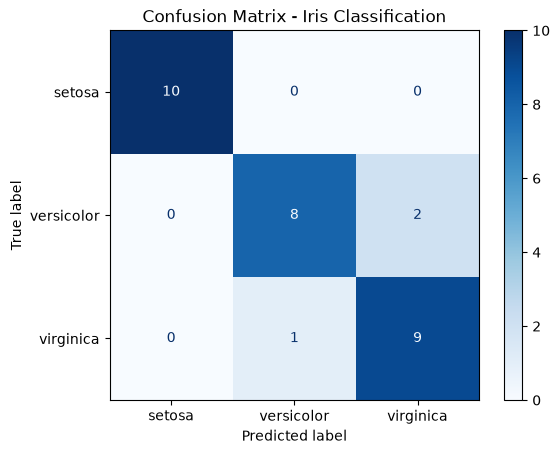


Sample Predictions:
-----------------------------------
Actual: 0  Predicted: 0  Probabilities: [0.999 0.001 0.   ]
Actual: 2  Predicted: 2  Probabilities: [0.002 0.098 0.9  ]
Actual: 1  Predicted: 1  Probabilities: [0.039 0.942 0.019]
Actual: 1  Predicted: 1  Probabilities: [0.015 0.974 0.011]
Actual: 0  Predicted: 0  Probabilities: [1. 0. 0.]
Actual: 1  Predicted: 2  Probabilities: [0.019 0.425 0.556]
Actual: 0  Predicted: 0  Probabilities: [1. 0. 0.]
Actual: 0  Predicted: 0  Probabilities: [0.996 0.003 0.   ]
Actual: 2  Predicted: 2  Probabilities: [0.    0.037 0.963]
Actual: 1  Predicted: 1  Probabilities: [0.042 0.553 0.405]


In [16]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay

# 1. Load dataset
iris = load_iris()
X = iris.data
y = iris.target

print("Dataset Shape:", X.shape)
print("Number of Classes:", len(np.unique(y)))

# Convert labels to one-hot encoding
Y = np.eye(3)[y]

# 2. Split dataset
X_train, X_test, Y_train, Y_test, y_train, y_test = train_test_split(
    X, Y, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# 3. Normalize data
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# 4. Initialize neural network
np.random.seed(42)

# Input layer: 4 features
# Hidden layer: 100 neurons
# Output layer: 3 classes

W1 = np.random.randn(4, 100) * np.sqrt(2 / 4)
b1 = np.zeros((1, 100))

W2 = np.random.randn(100, 3) * 0.01
b2 = np.zeros((1, 3))

learning_rate = 0.01
epochs = 1000

# 5. Activation functions
def relu(x):
    return np.maximum(0, x)

def relu_derivative(x):
    return (x > 0).astype(float)

def softmax(x):
    exp_x = np.exp(x - np.max(x, axis=1, keepdims=True))
    return exp_x / np.sum(exp_x, axis=1, keepdims=True)

# 6. Train the neural network
for epoch in range(epochs):

    # Forward propagation
    Z1 = np.dot(X_train, W1) + b1
    A1 = relu(Z1)

    Z2 = np.dot(A1, W2) + b2
    A2 = softmax(Z2)

    # Calculate cross-entropy loss
    loss = -np.mean(
        np.sum(Y_train * np.log(A2 + 1e-9), axis=1)
    )

    # Backpropagation
    dZ2 = (A2 - Y_train) / len(X_train)

    dW2 = np.dot(A1.T, dZ2)
    db2 = np.sum(dZ2, axis=0, keepdims=True)

    dA1 = np.dot(dZ2, W2.T)
    dZ1 = dA1 * relu_derivative(Z1)

    dW1 = np.dot(X_train.T, dZ1)
    db1 = np.sum(dZ1, axis=0, keepdims=True)

    # Update weights and biases using gradient descent
    W2 -= learning_rate * dW2
    b2 -= learning_rate * db2

    W1 -= learning_rate * dW1
    b1 -= learning_rate * db1

    # Display loss after every 200 epochs
    if (epoch + 1) % 100 == 0:
        print("Epoch:", epoch + 1, "Loss:", round(loss, 4))

# 7. Test the neural network
Z1_test = np.dot(X_test, W1) + b1
A1_test = relu(Z1_test)

Z2_test = np.dot(A1_test, W2) + b2
A2_test = softmax(Z2_test)

# Apply threshold
threshold = 0.5
threshold_output = (A2_test >= threshold).astype(int)

# Predict class with the highest probability
predictions = np.argmax(A2_test, axis=1)

# Actual class labels
y_actual = y_test

# 8. Calculate accuracy using accuracy_score
accuracy = accuracy_score(y_actual, predictions) * 100

print("\n===================================")
print("Neural Network Results")
print("===================================")

print("Hidden Neurons :", 100)
print("Activation     : ReLU")
print("Output Neurons :", 3)
print("Output Function: Softmax")
print("Optimizer      : Gradient Descent")
print("Learning Rate  :", learning_rate)
print("Epochs         :", epochs)

print("\nActual Classes:   ", y_actual)
print("Predicted Classes:", predictions)

print("Test Accuracy:", round(accuracy, 2), "%")

# 9. Confusion matrix
cm = confusion_matrix(y_actual, predictions)

print("\nConfusion Matrix:")
print(cm)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=iris.target_names
)

disp.plot(cmap="Blues")
plt.title("Confusion Matrix - Iris Classification")
plt.show()

# 10. Sample predictions
print("\nSample Predictions:")
print("-----------------------------------")

for i in range(min(10, len(X_test))):
    print(
        "Actual:", y_actual[i],
        " Predicted:", predictions[i],
        " Probabilities:", np.round(A2_test[i], 3)
    )
